# DrowsyNet: Driver Drowsiness Detection with Machine Learning

## Section 1: Project Introduction

**Problem statement.** Driver fatigue causes a large share of road accidents. In India alone there were more than 4.6 lakh road accidents in 2015, and the US NHTSA attributes around 100,000 crashes a year mainly to drowsy drivers. A drowsy driver reacts slowly, drifts out of lane and can fall asleep for a few seconds (a *micro-sleep*) without noticing.

**What driver drowsiness detection means.** Drowsiness detection watches the driver's face and decides whether they are alert or getting sleepy, early enough to warn them. The face gives clear signs of drowsiness: the eyelids close more and for longer, blinks get slower, the gaze drops, the head nods and the driver yawns.

**Objective.** Build and compare machine-learning models that classify each video frame of a driver's face as **Drowsy** or **Non Drowsy**, evaluated on drivers the models have **never seen** during training. Then choose the best model and save it for a Streamlit app.

**Input.** One row per video frame of the driver's face, with facial measurements:
* **EAR** (eye aspect ratio, left/right): eye opening. It drops towards 0 when the eye closes.
* **MAR** and **mouth opening**: rise during a yawn.
* **Head pose**: pitch / yaw / roll in degrees. Pitch changes when the head nods.
* **Facial-action scores** in [0, 1]: eye blink, eye squint, eye wide, gaze down/up, jaw open, mouth close, brow movements.
* **Image quality**: blur and brightness.
* **Identifiers**: `subject_id` (the driver), `frame` (position in the recording), `image` (file name).

**Output.** A label, **Drowsy** or **Non Drowsy**, and a confidence (probability).

**Dataset.** The measurements were extracted from the 41,793 face images of the Kaggle *Driver Drowsiness Dataset (DDD)*, which were cut from the videos of the UTA Real-Life Drowsiness Dataset (28 drivers). Each image was processed with Google MediaPipe Face Landmarker (478 facial landmarks, facial-action scores and head pose).

**Workflow**
```
CSV upload → inspection → cleaning → EDA
   → subject-independent split (no driver in both train and test)
   → feature engineering (derived eye features, rolling PERCLOS-style features, personal calibration)
   → 4 models: Logistic Regression · Random Forest · XGBoost · LSTM
   → comparison on unseen drivers → best model → save → predict_drowsiness()
```

## Section 2: Install Dependencies
Google Colab already includes most of these libraries. The cell installs only what is missing.

In [1]:
import importlib.util, subprocess, sys
required = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "sklearn": "scikit-learn", "xgboost": "xgboost", "tensorflow": "tensorflow", "joblib": "joblib"}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Installed:", missing if missing else "nothing — all packages were already available")

Installed: nothing — all packages were already available


## Section 3: Import Libraries

In [2]:
import os, glob, json, random, time, warnings, importlib.util
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve)
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow import keras

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")      # hide TensorFlow deprecation notices

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40, "display.width", 200)
IN_COLAB = importlib.util.find_spec("google.colab") is not None
print(f"TensorFlow {tf.__version__} | running in {'Google Colab' if IN_COLAB else 'a local Jupyter session'}")

TensorFlow 2.21.0 | running in a local Jupyter session


## Section 4: Load Dataset
In Colab, a file picker opens. Choose the CSV (`driver_drowsiness_features.csv`). Outside Colab, the notebook looks for a CSV in the current folder or in `data/`.

In [3]:
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
else:
    csv_files = sorted(glob.glob("*.csv")) + sorted(glob.glob("data/*.csv"))
assert csv_files, "No CSV file found — please upload the dataset CSV."
CSV_PATH = csv_files[0]
df_raw = pd.read_csv(CSV_PATH)
print(f"Loaded: {CSV_PATH}  →  {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

Loaded: data\driver_drowsiness_features.csv  →  41,793 rows × 29 columns


## Section 5: Dataset Inspection

In [4]:
print("Shape:", df_raw.shape)
print("\nFirst 5 rows:"); display(df_raw.head())
print("Last 5 rows:"); display(df_raw.tail())

Shape: (41793, 29)

First 5 rows:


,image,subject_id,frame,label,ear_left,ear_right,mar,mouth_open,head_pitch,head_yaw,head_roll,eye_blink_left,eye_blink_right,eye_squint_left,eye_squint_right,eye_wide_left,eye_wide_right,gaze_down_left,gaze_down_right,gaze_up_left,gaze_up_right,jaw_open,mouth_close,brow_down_left,brow_down_right,brow_inner_up,face_scale,image_blur,image_brightness
0,A0001.png,A,1,Drowsy,0.24703,0.23590,0.00796,0.00378,-12.95033,-1.43785,-0.43083,0.27727,0.29166,0.24641,0.22000,0.00439,0.00244,0.61083,0.56498,0.01399,0.00942,0.01149,0.00154,0.01325,0.01142,0.17336,0.96962,69.46108,78.63461
1,A0002.png,A,2,Drowsy,0.26246,0.26242,0.00599,0.00251,-11.49118,-1.04346,-1.16237,0.24585,0.25191,0.28085,0.21833,0.00493,0.00289,0.51563,0.46037,0.02120,0.01390,0.01870,0.00172,0.01144,0.00796,0.20165,0.94521,83.73459,80.79860
2,A0003.png,A,3,Drowsy,0.28051,0.28119,0.00544,0.00168,-8.79588,-1.23059,-0.96635,0.17782,0.20876,0.36809,0.23435,0.00709,0.00332,0.37298,0.34695,0.03409,0.02261,0.01274,0.00119,0.01132,0.00944,0.18139,0.96827,73.02921,80.90487
3,A0004.png,A,4,Drowsy,0.29914,0.29036,0.00726,0.00295,-7.50488,-0.97646,-0.75791,0.14455,0.19462,0.36931,0.24242,0.00746,0.00317,0.44274,0.41311,0.02492,0.01445,0.01885,0.00235,0.08724,0.05356,0.04968,0.97229,70.95601,82.30571
4,A0005.png,A,5,Drowsy,0.34391,0.34174,0.00664,0.00241,-8.53966,-1.40740,-0.76333,0.06157,0.06328,0.25685,0.11378,0.01900,0.01258,0.42378,0.38643,0.02490,0.01543,0.01931,0.00231,0.04759,0.03792,0.08938,0.95771,71.49914,82.17361


Last 5 rows:


,image,subject_id,frame,label,ear_left,ear_right,mar,mouth_open,head_pitch,head_yaw,head_roll,eye_blink_left,eye_blink_right,eye_squint_left,eye_squint_right,eye_wide_left,eye_wide_right,gaze_down_left,gaze_down_right,gaze_up_left,gaze_up_right,jaw_open,mouth_close,brow_down_left,brow_down_right,brow_inner_up,face_scale,image_blur,image_brightness
41788,zc1703.png,ZC,1703,Non Drowsy,0.40031,0.40636,0.00848,0.00208,1.76884,1.68772,-1.73869,0.02985,0.00944,0.24910,0.12245,0.02632,0.05658,0.04358,0.04597,0.19223,0.19607,0.10154,0.05904,0.00022,0.00014,0.47370,0.94922,115.12611,108.72592
41789,zc1704.png,ZC,1704,Non Drowsy,0.39361,0.39934,0.00943,0.00265,1.54333,1.75572,-1.98087,0.03532,0.01061,0.26403,0.13135,0.02362,0.05014,0.05236,0.05610,0.16580,0.16957,0.09670,0.05667,0.00016,0.00010,0.49581,0.95330,110.43348,108.39589
41790,zc1705.png,ZC,1705,Non Drowsy,0.39373,0.39337,0.00723,0.00171,1.05153,1.69832,-2.02382,0.04163,0.01380,0.26174,0.14528,0.02062,0.04616,0.06102,0.06876,0.14529,0.14889,0.13199,0.08526,0.00030,0.00021,0.43996,0.99923,106.43159,106.99243
41791,zc1706.png,ZC,1706,Non Drowsy,0.39701,0.40373,0.00804,0.00217,1.16599,1.75003,-1.97187,0.03057,0.00848,0.23275,0.12540,0.02632,0.06451,0.05398,0.05542,0.16020,0.16898,0.11933,0.07555,0.00025,0.00018,0.46929,0.97953,111.79402,108.17551
41792,zc1707.png,ZC,1707,Non Drowsy,0.41136,0.40943,0.00636,0.00180,2.58238,0.86365,-0.43933,0.01978,0.00838,0.22122,0.10087,0.03671,0.05698,0.04058,0.06368,0.19210,0.15314,0.13680,0.10068,0.00059,0.00043,0.34213,1.01291,107.89162,109.15855


In [5]:
info = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum(),
                     "missing_%": (df_raw.isna().mean() * 100).round(3), "unique": df_raw.nunique()})
display(info)
print("Duplicate rows (all columns identical):", df_raw.duplicated().sum())
display(df_raw.describe().T.round(3))

,dtype,missing,missing_%,unique
image,str,0,0.00,41793
subject_id,str,0,0.00,28
frame,int64,0,0.00,1760
label,str,0,0.00,2
ear_left,float64,4,0.01,21944
ear_right,float64,4,0.01,22069
mar,float64,4,0.01,5879
mouth_open,float64,4,0.01,3314
head_pitch,float64,4,0.01,41515
head_yaw,float64,4,0.01,41205


Duplicate rows (all columns identical): 0


,count,mean,std,min,25%,50%,75%,max
frame,41793.0,527.527,387.241,1.000,212.000,445.000,791.000,1760.000
ear_left,41789.0,0.246,0.086,0.002,0.207,0.245,0.291,0.576
ear_right,41789.0,0.245,0.088,0.003,0.208,0.246,0.292,0.511
mar,41789.0,0.014,0.032,0.000,0.004,0.006,0.011,0.753
mouth_open,41789.0,0.005,0.010,0.000,0.001,0.002,0.004,0.255
head_pitch,41789.0,-5.617,8.809,-33.347,-11.902,-5.478,0.394,27.794
head_yaw,41789.0,-0.015,5.678,-21.476,-3.313,0.046,2.493,36.085
head_roll,41789.0,0.495,4.064,-25.288,-1.910,0.540,2.916,18.086
eye_blink_left,41789.0,0.217,0.179,0.002,0.102,0.163,0.278,0.880
eye_blink_right,41789.0,0.200,0.182,0.001,0.068,0.145,0.274,0.844


### Identifying the target and the ID columns
The notebook detects these columns automatically. **If detection is wrong, change the three variables below by hand.**
* **Target**: a categorical column with few values whose name or values mention drowsiness / label / class.
* **Subject column**: the person each row belongs to. It is used to keep every driver entirely in train or entirely in test.
* **Order column**: frame number or timestamp. It is used for time-based features and for the LSTM sequences.

In [6]:
def detect_target(df):
    for c in df.columns:
        vals = df[c].dropna().astype(str).str.lower()
        if df[c].nunique() <= 10 and (any(k in c.lower() for k in ("label", "class", "target", "state", "drows"))
                                      or vals.str.contains("drows").any()):
            return c
    return None

def detect_col(df, keywords, exclude=()):
    for c in df.columns:
        if c not in exclude and any(k in c.lower() for k in keywords):
            return c
    return None

TARGET_COL = detect_target(df_raw)
SUBJECT_COL = detect_col(df_raw, ("subject", "participant", "person", "driver", "user"), exclude=(TARGET_COL,))
ORDER_COL = detect_col(df_raw, ("frame", "timestamp", "time"), exclude=(TARGET_COL, SUBJECT_COL))
ID_COLS = [c for c in df_raw.columns if c not in (TARGET_COL, SUBJECT_COL, ORDER_COL)
           and df_raw[c].dtype == object and df_raw[c].nunique() > 0.5 * len(df_raw)]   # e.g. file names
print(f"TARGET_COL  = {TARGET_COL!r}\nSUBJECT_COL = {SUBJECT_COL!r}\nORDER_COL   = {ORDER_COL!r}\nID columns (not features) = {ID_COLS}")

TARGET_COL  = 'label'
SUBJECT_COL = 'subject_id'
ORDER_COL   = 'frame'
ID columns (not features) = []


In [7]:
counts = df_raw[TARGET_COL].value_counts()
display(pd.DataFrame({"count": counts, "share_%": (counts / counts.sum() * 100).round(2)}))
print(f"{df_raw[SUBJECT_COL].nunique()} subjects (drivers). Images per subject and class:")
display(df_raw.groupby([SUBJECT_COL, TARGET_COL]).size().unstack(fill_value=0).T)

,count,share_%
label,,
Drowsy,22348,53.47
Non Drowsy,19445,46.53


28 subjects (drivers). Images per subject and class:


subject_id,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,T,U,V,W,X,Y,ZA,ZB,ZC
label,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Drowsy,1411,315,335,179,962,415,499,508,1095,474,630,732,777,1156,1097,963,562,204,487,933,420,653,1162,1749,1112,621,1551,1346
Non Drowsy,1252,409,400,1005,1000,0,109,571,1045,717,538,381,473,957,671,190,521,522,457,0,510,1002,493,1143,1500,1054,1237,1288


## Section 6: Data Cleaning
Decisions:
* **Missing values.** A few rows have *all* measurements missing, because the face detector found no face in those images. There's nothing to learn from them, so they are removed. Any other single missing value is filled with the training-set median inside the model pipelines, so the test set never influences it.
* **Invalid values.** Eye aspect ratios and facial-action scores must lie in [0, 1], head angles within ±90°, and blur / brightness must be non-negative. Values outside these ranges are physically impossible, so they are set to missing (then median-imputed), not deleted with the whole row.
* **Duplicates.** Rows that are identical in every column (including image name) would be true duplicates and are removed. Rows with identical *measurements* but different frames are kept: consecutive video frames can genuinely look the same.
* **Categorical variables.** The target is encoded as **Non Drowsy = 0, Drowsy = 1**, so "positive" means drowsy. `subject_id` is **not** a feature: a model that learns driver identities can't work on a new driver. It is used only to split the data. The image file name is only an identifier.
* **Class imbalance.** Checked below. Every model also gets class weighting (`class_weight="balanced"` / `scale_pos_weight`) so it can't favour the larger class.

In [8]:
df = df_raw.copy()
FEATURES_RAW = [c for c in df.columns if c not in [TARGET_COL, SUBJECT_COL, ORDER_COL] + ID_COLS
                and pd.api.types.is_numeric_dtype(df[c])]
print(f"{len(FEATURES_RAW)} numeric measurement columns:", FEATURES_RAW)

before = len(df)
all_missing = df[FEATURES_RAW].isna().all(axis=1)
df = df[~all_missing]
df = df.drop_duplicates()
print(f"Removed {all_missing.sum()} rows with no measurements and {before - all_missing.sum() - len(df)} exact duplicates")

RANGES = {c: (0, 1) for c in FEATURES_RAW if c.startswith(("ear_", "eye_", "gaze_", "jaw_", "mouth_close", "brow_"))}
RANGES.update({c: (-90, 90) for c in FEATURES_RAW if c.startswith("head_")})
RANGES.update({c: (0, None) for c in ("mar", "mouth_open", "face_scale", "image_blur", "image_brightness") if c in FEATURES_RAW})

def invalid_mask(values, lo, hi):
    bad = pd.Series(False, index=values.index)
    if lo is not None:
        bad |= values < lo
    if hi is not None:
        bad |= values > hi
    return bad

def clean_invalid(frame, ranges=RANGES):
    frame = frame.copy()
    for c, (lo, hi) in ranges.items():
        frame.loc[invalid_mask(frame[c], lo, hi), c] = np.nan
    return frame

invalid = {c: int(invalid_mask(df[c], lo, hi).sum()) for c, (lo, hi) in RANGES.items()}
df = clean_invalid(df)
print("Invalid values set to missing:", {k: v for k, v in invalid.items() if v} or "none")

label_encoder = LabelEncoder()
classes = sorted(df[TARGET_COL].unique(), key=lambda v: ("drows" in str(v).lower() and "non" not in str(v).lower()))
label_encoder.classes_ = np.array(classes)          # index 0 = Non Drowsy, index 1 = Drowsy
df["y"] = label_encoder.transform(df[TARGET_COL])
POS_LABEL = label_encoder.classes_[1]
ratio = df["y"].mean()
print(f"Encoding: {dict(zip(label_encoder.classes_, range(2)))} | Drowsy share {ratio:.1%} → "
      f"{'mild' if 0.35 < ratio < 0.65 else 'strong'} imbalance, handled with class weights")

25 numeric measurement columns: ['ear_left', 'ear_right', 'mar', 'mouth_open', 'head_pitch', 'head_yaw', 'head_roll', 'eye_blink_left', 'eye_blink_right', 'eye_squint_left', 'eye_squint_right', 'eye_wide_left', 'eye_wide_right', 'gaze_down_left', 'gaze_down_right', 'gaze_up_left', 'gaze_up_right', 'jaw_open', 'mouth_close', 'brow_down_left', 'brow_down_right', 'brow_inner_up', 'face_scale', 'image_blur', 'image_brightness']


Removed 0 rows with no measurements and 0 exact duplicates


Invalid values set to missing: none


Encoding: {np.str_('Non Drowsy'): 0, np.str_('Drowsy'): 1} | Drowsy share 53.5% → mild imbalance, handled with class weights


## Section 7: Exploratory Data Analysis

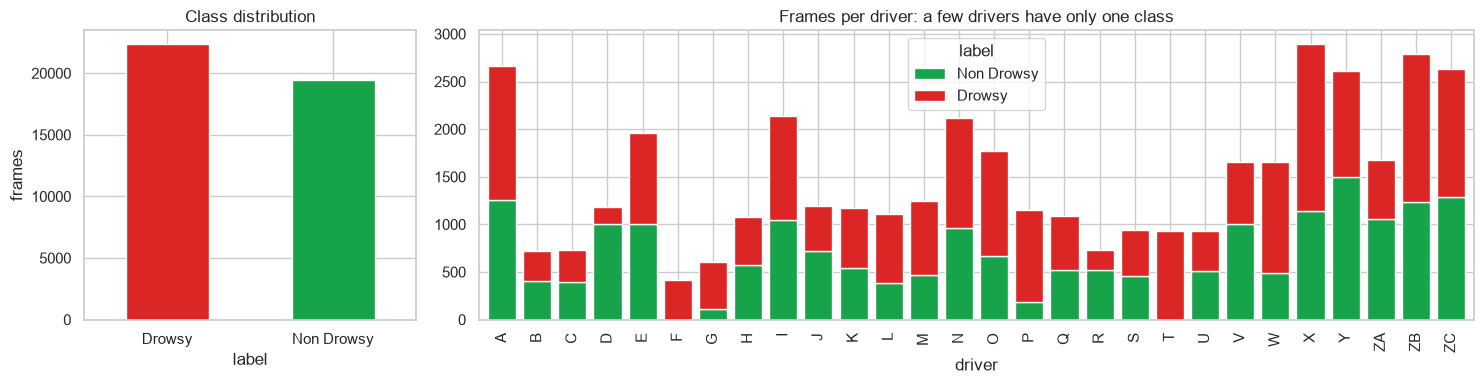

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 3]})
df[TARGET_COL].value_counts().plot.bar(ax=axes[0], color=["#dc2626", "#16a34a"], rot=0)
axes[0].set_title("Class distribution"); axes[0].set_ylabel("frames")
df.groupby([SUBJECT_COL, TARGET_COL]).size().unstack(fill_value=0)[list(label_encoder.classes_)] \
  .plot.bar(stacked=True, ax=axes[1], color=["#16a34a", "#dc2626"], width=0.8)
axes[1].set_title("Frames per driver: a few drivers have only one class"); axes[1].set_xlabel("driver")
plt.tight_layout(); plt.show()

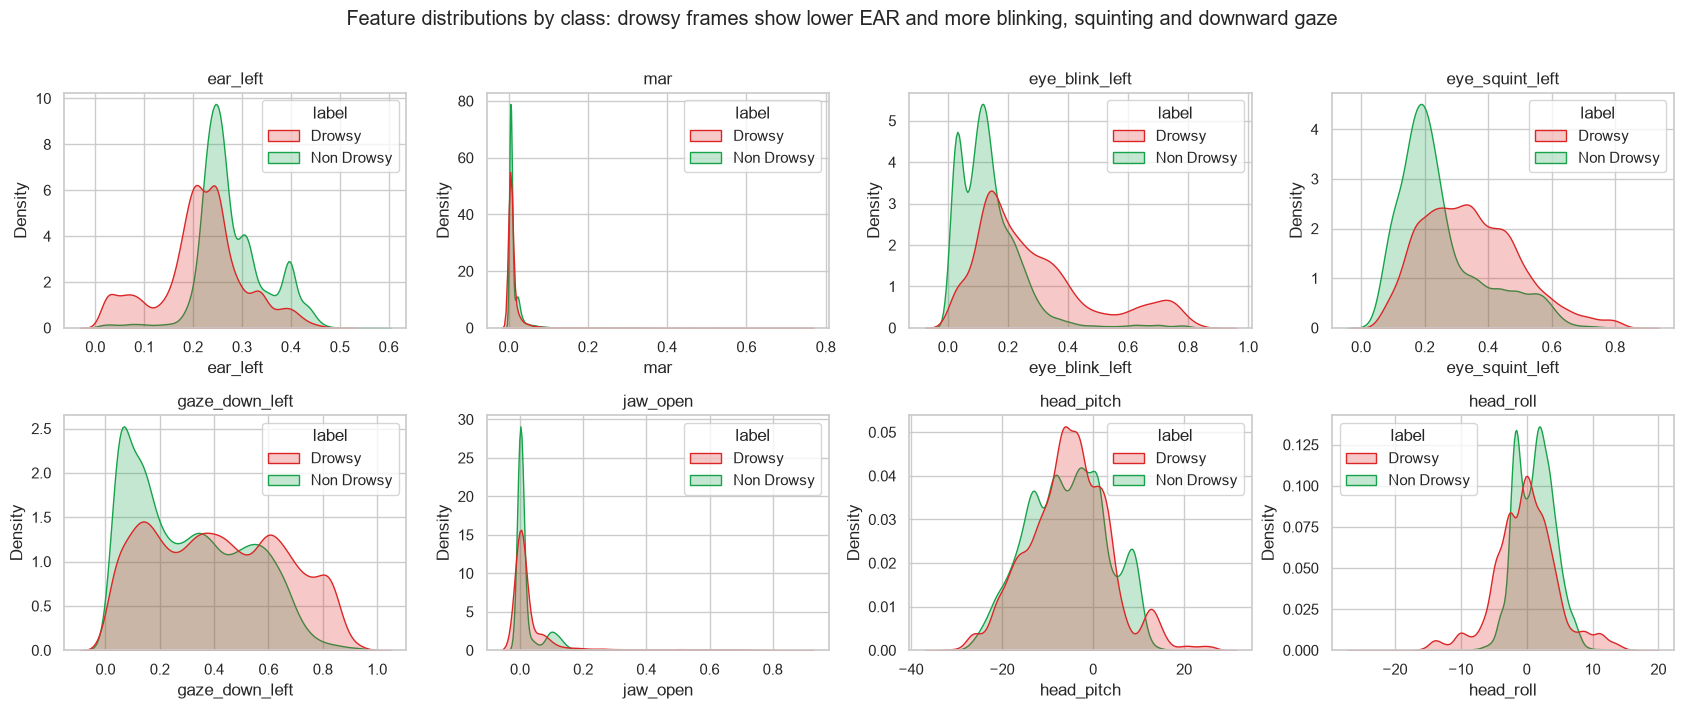

In [10]:
key = [c for c in ["ear_left", "mar", "eye_blink_left", "eye_squint_left", "gaze_down_left", "jaw_open", "head_pitch", "head_roll"] if c in df]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), key):
    sns.kdeplot(data=df, x=c, hue=TARGET_COL, ax=ax, fill=True, common_norm=False, palette={label_encoder.classes_[0]: "#16a34a", POS_LABEL: "#dc2626"})
    ax.set_title(c)
plt.suptitle("Feature distributions by class: drowsy frames show lower EAR and more blinking, squinting and downward gaze", y=1.01)
plt.tight_layout(); plt.show()

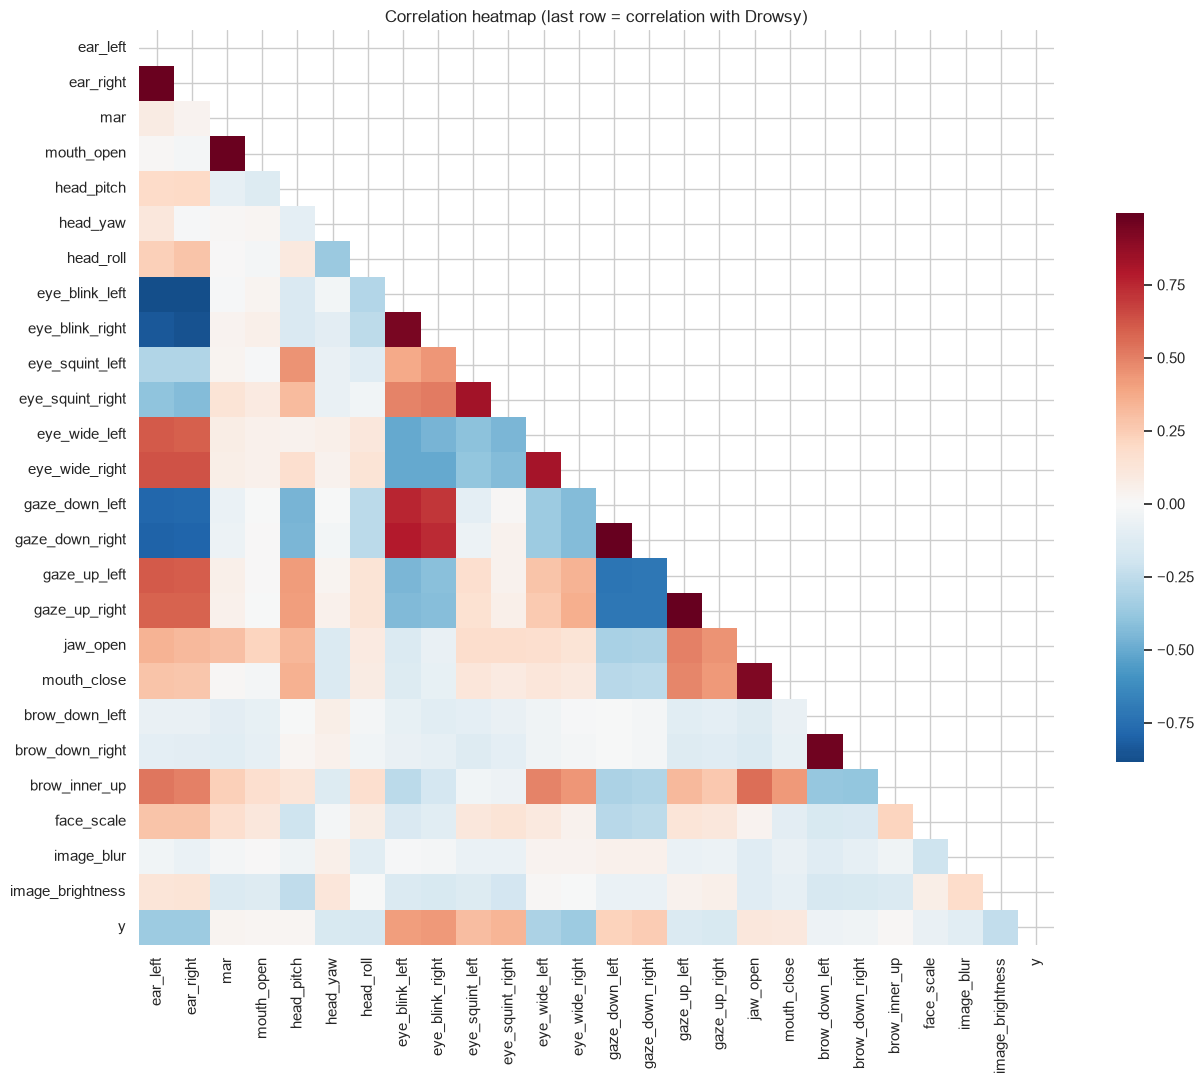

Strongest correlations with the Drowsy label:


,corr_with_drowsy
eye_blink_right,0.436
eye_blink_left,0.412
ear_left,-0.362
ear_right,-0.359
eye_wide_right,-0.356
eye_squint_right,0.334
eye_wide_left,-0.317
eye_squint_left,0.307


In [11]:
plt.figure(figsize=(14, 11))
corr = df[FEATURES_RAW + ["y"]].corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, mask=np.triu(np.ones_like(corr, dtype=bool)), square=True, cbar_kws={"shrink": .6})
plt.title("Correlation heatmap (last row = correlation with Drowsy)"); plt.tight_layout(); plt.show()
print("Strongest correlations with the Drowsy label:")
display(corr["y"].drop("y").sort_values(key=abs, ascending=False).head(8).round(3).to_frame("corr_with_drowsy"))

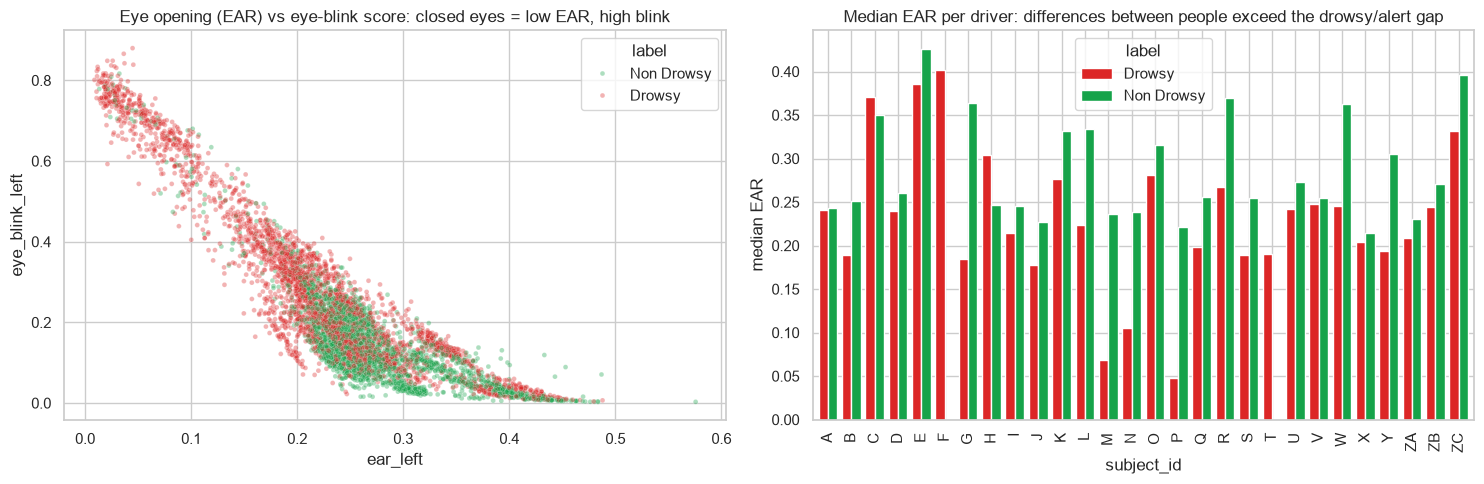

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sample = df.sample(6000, random_state=SEED)
sns.scatterplot(data=sample, x="ear_left", y="eye_blink_left", hue=TARGET_COL, alpha=0.35, s=12, ax=axes[0],
                palette={label_encoder.classes_[0]: "#16a34a", POS_LABEL: "#dc2626"})
axes[0].set_title("Eye opening (EAR) vs eye-blink score: closed eyes = low EAR, high blink")
per = df.groupby([SUBJECT_COL, TARGET_COL])["ear_left"].median().unstack()
per.plot.bar(ax=axes[1], color=["#dc2626", "#16a34a"], width=0.8)
axes[1].set_title("Median EAR per driver: differences between people exceed the drowsy/alert gap")
axes[1].set_ylabel("median EAR"); plt.tight_layout(); plt.show()

**The most important EDA finding.** The right-hand plot shows that a person's normal eye opening differs a lot from one driver to the next. One driver's *alert* EAR can be lower than another driver's *drowsy* EAR. A model that compares raw values across people is confused by this, which motivates the **personal calibration** features in Section 9.

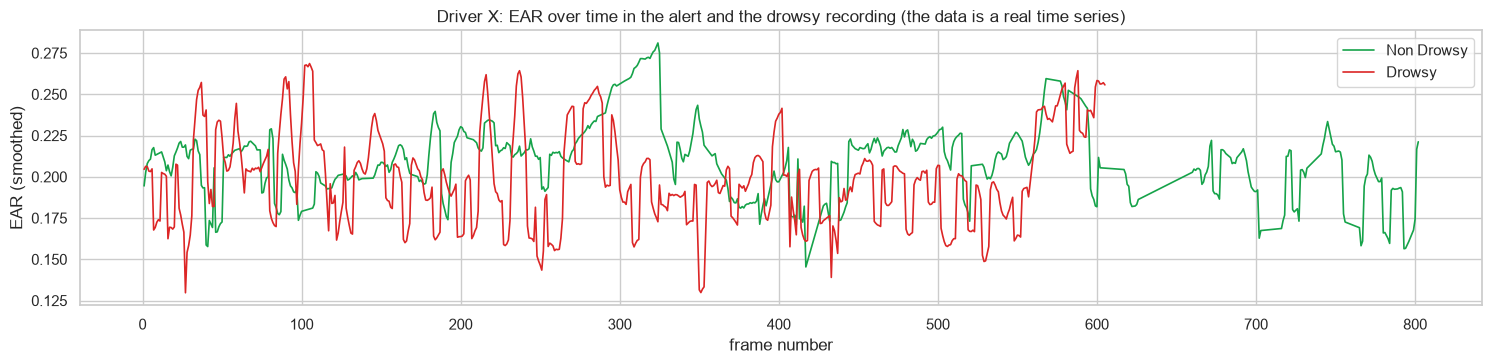

In [13]:
s0 = df[SUBJECT_COL].value_counts().index[0]
fig, ax = plt.subplots(figsize=(15, 3.8))
for lbl, color in [(label_encoder.classes_[0], "#16a34a"), (POS_LABEL, "#dc2626")]:
    seg = df[(df[SUBJECT_COL] == s0) & (df[TARGET_COL] == lbl)].sort_values(ORDER_COL)
    ax.plot(seg[ORDER_COL].to_numpy()[:600], seg["ear_left"].rolling(5, min_periods=1).mean().to_numpy()[:600], color=color, label=lbl, lw=1.2)
ax.set_xlabel("frame number"); ax.set_ylabel("EAR (smoothed)"); ax.legend()
ax.set_title(f"Driver {s0}: EAR over time in the alert and the drowsy recording (the data is a real time series)")
plt.tight_layout(); plt.show()

## Section 8: Data Leakage Prevention
The dataset has many frames per driver (`subject_id`), and consecutive frames from one recording are nearly identical (`frame`). If frames were split **randomly**, almost-identical frames of the same person would land in both training and test. The model would then just recognise the person and the moment, giving inflated accuracies close to 99 % that collapse on a new driver.

The split is therefore **subject-independent**, done with `GroupShuffleSplit` on `subject_id`:
* **Test set**: about 20 % of the drivers, with all of their frames. It isn't touched until the final evaluation.
* **Validation set**: about 15 % of the *training* drivers, used only for LSTM early stopping.
* **Cross-validation**: 5-fold `GroupKFold` over the training drivers, to measure how stable each classic model is across people.

Two more leakage rules:
* Time-based features and LSTM sequences are computed **within one recording of one driver only**. They never cross drivers or recordings.
* Calibration frames (Section 9) are **removed** from training and testing, so no model is ever scored on a frame used to calibrate it.

In [14]:
# Recordings ("clips"): consecutive frames of one driver and class; a jump of more than 5 frames starts a new clip
df = df.sort_values([SUBJECT_COL, TARGET_COL, ORDER_COL]).reset_index(drop=True)
gap = df.groupby([SUBJECT_COL, TARGET_COL])[ORDER_COL].diff()
df["clip"] = (gap.isna() | (gap > 5)).cumsum()
df["pos_in_clip"] = df.groupby("clip").cumcount()
print(f"{df['clip'].nunique()} continuous recordings (clips); median length {df.groupby('clip').size().median():.0f} frames")

280 continuous recordings (clips); median length 54 frames


## Section 9: Feature Engineering
All engineered features are computed from the measurements in the dataset:

1. **Derived per-frame features**
   * `ear_mean` (average eye opening) and `ear_asymmetry` (|left − right|, one eye drooping)
   * `eye_closure` (mean blink score of both eyes), `gaze_down` (mean downward gaze), `squint` (mean squint)
2. **Rolling (temporal) features** over the last 30 frames of the *same clip*, using past frames only, so a live system could compute them:
   * `perclos_30`: the fraction of frames with eyes mostly closed (eye closure > 0.5). This is the PERCLOS measure, one of the most validated drowsiness indicators.
   * `ear_roll_mean`, `closure_roll_mean`: average eye opening and closure over the window
   * `pitch_roll_std`: head-pitch variability (nodding)
   * `jaw_roll_max`: the largest jaw opening in the window (yawning)
3. **Personal calibration (z-scores against the driver's own alert baseline).** The EDA showed that differences between people dominate. When a drive starts, a real system first records a few seconds of the driver **alert**, and here that is mirrored with the **first 20 % of each driver's alert frames** (at least 30). Each driver's per-feature median and standard deviation define their baseline, and every frame gets `z_feature = (value − driver's median) / driver's std`. A z-score says how much *this* driver's face has changed from their own normal.
   * Calibration frames are removed from training and testing.
   * Drivers with **no alert frames** can't be calibrated and are excluded (they have no baseline). This affects 2 of the 28 drivers.
   * For a new driver without calibration, `predict_drowsiness()` falls back to the *average* baseline of the training drivers.

In [15]:
WINDOW = 30           # rolling window and LSTM sequence length (frames)
CALIB_FRACTION, CALIB_MIN = 0.20, 30

def add_frame_features(frame):
    frame = frame.copy()
    frame["ear_mean"] = (frame["ear_left"] + frame["ear_right"]) / 2
    frame["ear_asymmetry"] = (frame["ear_left"] - frame["ear_right"]).abs()
    frame["eye_closure"] = (frame["eye_blink_left"] + frame["eye_blink_right"]) / 2
    frame["gaze_down"] = (frame["gaze_down_left"] + frame["gaze_down_right"]) / 2
    frame["squint"] = (frame["eye_squint_left"] + frame["eye_squint_right"]) / 2
    return frame

def add_rolling_features(frame, group_col="clip", window=WINDOW):
    """Causal rolling statistics inside each clip (never across drivers or recordings)."""
    frame = frame.copy()
    g = frame.groupby(group_col, sort=False)
    roll = lambda col, fn: g[col].transform(lambda s: fn(s.rolling(window, min_periods=1)))
    frame["perclos_30"] = g["eye_closure"].transform(lambda s: (s > 0.5).astype(float).rolling(window, min_periods=1).mean())
    frame["ear_roll_mean"] = roll("ear_mean", lambda r: r.mean())
    frame["closure_roll_mean"] = roll("eye_closure", lambda r: r.mean())
    frame["pitch_roll_std"] = g["head_pitch"].transform(lambda s: s.rolling(window, min_periods=2).std()).fillna(0.0)
    frame["jaw_roll_max"] = roll("jaw_open", lambda r: r.max())
    return frame

df = add_rolling_features(add_frame_features(df))
DERIVED = ["ear_mean", "ear_asymmetry", "eye_closure", "gaze_down", "squint"]
ROLLING = ["perclos_30", "ear_roll_mean", "closure_roll_mean", "pitch_roll_std", "jaw_roll_max"]
CALIB_BASE = FEATURES_RAW + DERIVED                       # features that get a personal z-score
Z_FEATURES = [f"z_{c}" for c in CALIB_BASE]

# --- personal calibration frames: first 20 % (min 30) of each driver's alert frames, in recording order
df["calib"] = False
for s, g in df[df["y"] == 0].groupby(SUBJECT_COL):
    df.loc[g.index[: max(CALIB_MIN, int(CALIB_FRACTION * len(g)))], "calib"] = True
baseline_median = df[df["calib"]].groupby(SUBJECT_COL)[CALIB_BASE].median()
baseline_std = df[df["calib"]].groupby(SUBJECT_COL)[CALIB_BASE].std().fillna(0) + 1e-3
no_baseline = sorted(set(df[SUBJECT_COL]) - set(baseline_median.index))
print("Drivers without alert frames (excluded, cannot be calibrated):", no_baseline)

df = df[df[SUBJECT_COL].isin(baseline_median.index)].copy()
med = baseline_median.loc[df[SUBJECT_COL]].to_numpy()
sd = baseline_std.loc[df[SUBJECT_COL]].to_numpy()
df[Z_FEATURES] = np.clip((df[CALIB_BASE].to_numpy() - med) / sd, -50, 50)

FEATURES = FEATURES_RAW + DERIVED + ROLLING + Z_FEATURES
print(f"Final feature set: {len(FEATURES)} features = {len(FEATURES_RAW)} raw + {len(DERIVED)} derived + "
      f"{len(ROLLING)} rolling + {len(Z_FEATURES)} calibrated z-scores")

Drivers without alert frames (excluded, cannot be calibrated): ['F', 'T']
Final feature set: 65 features = 25 raw + 5 derived + 5 rolling + 30 calibrated z-scores


In [16]:
# --- subject-independent split (Section 8)
model_df = df[~df["calib"]].reset_index(drop=True)                 # calibration frames are never trained on or scored
model_df["pos_eval"] = model_df.groupby("clip").cumcount()          # position among the frames that remain in each clip
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trv_idx, test_idx = next(gss.split(model_df, model_df["y"], model_df[SUBJECT_COL]))
train_val, test = model_df.iloc[trv_idx], model_df.iloc[test_idx]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_idx, val_idx = next(gss_val.split(train_val, train_val["y"], train_val[SUBJECT_COL]))
train, val = train_val.iloc[tr_idx], train_val.iloc[val_idx]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:<10}: {part[SUBJECT_COL].nunique():>2} drivers {sorted(part[SUBJECT_COL].unique())}  "
          f"{len(part):>6,} frames  drowsy {part['y'].mean():.1%}")
assert not set(train_val[SUBJECT_COL]) & set(test[SUBJECT_COL]), "a driver appears in both train and test!"
assert not set(train[SUBJECT_COL]) & set(val[SUBJECT_COL])
print("✓ No driver appears in more than one set.")

# Population baseline (average of the TRAINING drivers) for drivers without personal calibration
train_drivers = sorted(train_val[SUBJECT_COL].unique())
POP_BASELINE = (baseline_median.loc[train_drivers].median(), baseline_std.loc[train_drivers].median())

# All four models are scored on the same test frames: frames with a full 30-frame history in their clip,
# because the LSTM needs 30 frames of context and the rolling features are complete there.
test_eval = test[test["pos_eval"] >= WINDOW - 1]
print(f"\nEvaluation frames (full {WINDOW}-frame history): {len(test_eval):,} of {len(test):,} test frames")

X_train, y_train = train_val[FEATURES], train_val["y"]
X_test, y_test = test_eval[FEATURES], test_eval["y"]
groups = train_val[SUBJECT_COL]

train     : 17 drivers ['C', 'D', 'E', 'G', 'H', 'I', 'L', 'N', 'O', 'P', 'Q', 'S', 'U', 'V', 'X', 'ZA', 'ZC']  23,203 frames  drowsy 57.6%
validation:  3 drivers ['B', 'W', 'Y']   4,512 frames  drowsy 57.4%
test      :  6 drivers ['A', 'J', 'K', 'M', 'R', 'ZB']   8,841 frames  drowsy 57.1%
✓ No driver appears in more than one set.

Evaluation frames (full 30-frame history): 8,029 of 8,841 test frames


### Shared evaluation helpers

In [17]:
RESULTS, PREDICTIONS = {}, {}

def evaluate(name, y_true, prob, threshold=0.5, cv_f1=None):
    pred = (prob >= threshold).astype(int)
    m = {"Model": name, "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
         "Recall": recall_score(y_true, pred, zero_division=0), "F1-Score": f1_score(y_true, pred, zero_division=0),
         "ROC-AUC": roc_auc_score(y_true, prob), "CV F1 (train drivers)": cv_f1}
    RESULTS[name], PREDICTIONS[name] = m, prob
    print(f"{name}: accuracy {m['Accuracy']:.2%} | precision {m['Precision']:.2%} | recall {m['Recall']:.2%} | "
          f"F1 {m['F1-Score']:.2%} | ROC-AUC {m['ROC-AUC']:.3f}" + (f" | CV F1 {cv_f1:.2%}" if cv_f1 is not None else ""))
    print(classification_report(y_true, pred, target_names=label_encoder.classes_, digits=3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title(f"{name}: confusion matrix")
    fpr, tpr, _ = roc_curve(y_true, prob)
    axes[1].plot(fpr, tpr, lw=2); axes[1].plot([0, 1], [0, 1], "--", color="grey")
    axes[1].set_title(f"ROC curve (AUC {m['ROC-AUC']:.3f})"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
    plt.tight_layout(); plt.show()
    return m

def group_cv_f1(make_model, X, y, groups, folds=5):
    """Mean F1 over subject-grouped folds of the TRAINING drivers (generalisation to new people)."""
    scores = []
    for a, b in GroupKFold(folds).split(X, y, groups):
        m = make_model().fit(X.iloc[a], y.iloc[a])
        scores.append(f1_score(y.iloc[b], m.predict(X.iloc[b])))
    return float(np.mean(scores)), float(np.std(scores))

def plot_importance(names, values, title, top=15):
    imp = pd.Series(values, index=names).sort_values(ascending=False).head(top)
    plt.figure(figsize=(8, 5)); imp[::-1].plot.barh(color="#2563eb"); plt.title(title); plt.tight_layout(); plt.show()
    return imp

## Section 10: Model 1, Logistic Regression (baseline)
A linear model on standardised features. It is fast and interpretable, and serves as the reference point.

trained in 4.9 s
Logistic Regression: accuracy 57.90% | precision 79.44% | recall 34.78% | F1 48.38% | ROC-AUC 0.715 | CV F1 64.32%
              precision    recall  f1-score   support

  Non Drowsy      0.508     0.882     0.645      3475
      Drowsy      0.794     0.348     0.484      4554

    accuracy                          0.579      8029
   macro avg      0.651     0.615     0.564      8029
weighted avg      0.670     0.579     0.553      8029



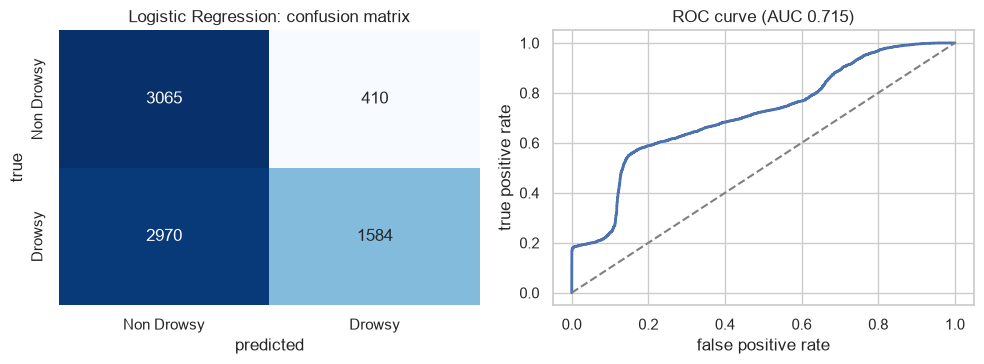

In [18]:
make_lr = lambda: Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                            ("model", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5))])
t0 = time.time()
lr_cv = group_cv_f1(make_lr, X_train, y_train, groups)
lr_model = make_lr().fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f} s")
evaluate("Logistic Regression", y_test, lr_model.predict_proba(X_test)[:, 1], cv_f1=lr_cv[0]);

## Section 11: Model 2, Random Forest
An ensemble of decision trees. It captures non-linear rules such as "eyes closed **and** head dropping".

trained in 44.8 s


Random Forest: accuracy 88.80% | precision 96.82% | recall 82.98% | F1 89.37% | ROC-AUC 0.961 | CV F1 82.63%
              precision    recall  f1-score   support

  Non Drowsy      0.812     0.964     0.882      3475
      Drowsy      0.968     0.830     0.894      4554

    accuracy                          0.888      8029
   macro avg      0.890     0.897     0.888      8029
weighted avg      0.901     0.888     0.889      8029



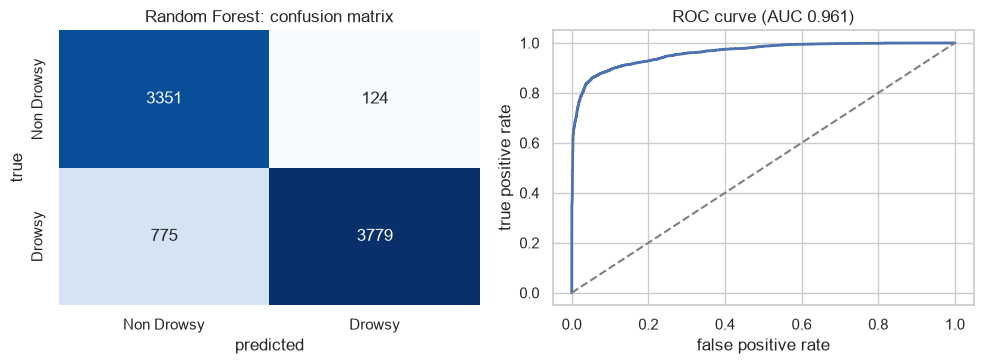

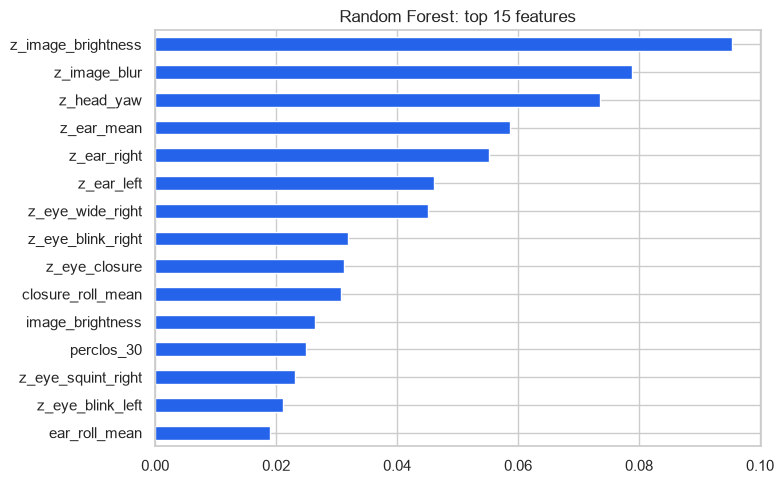

In [19]:
make_rf = lambda: Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("model", RandomForestClassifier(n_estimators=250, max_depth=18, min_samples_leaf=3,
                                                             class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
t0 = time.time()
rf_cv = group_cv_f1(make_rf, X_train, y_train, groups)
rf_model = make_rf().fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f} s")
evaluate("Random Forest", y_test, rf_model.predict_proba(X_test)[:, 1], cv_f1=rf_cv[0])
rf_imp = plot_importance(FEATURES, rf_model.named_steps["model"].feature_importances_, "Random Forest: top 15 features")

## Section 12: Model 3, XGBoost
Gradient-boosted trees: each new tree corrects the errors of the previous ones. `scale_pos_weight` balances the classes, and moderate depth with row/column subsampling limits overfitting.

trained in 21.8 s
XGBoost: accuracy 90.34% | precision 97.99% | recall 84.69% | F1 90.86% | ROC-AUC 0.956 | CV F1 79.99%
              precision    recall  f1-score   support

  Non Drowsy      0.830     0.977     0.897      3475
      Drowsy      0.980     0.847     0.909      4554

    accuracy                          0.903      8029
   macro avg      0.905     0.912     0.903      8029
weighted avg      0.915     0.903     0.904      8029



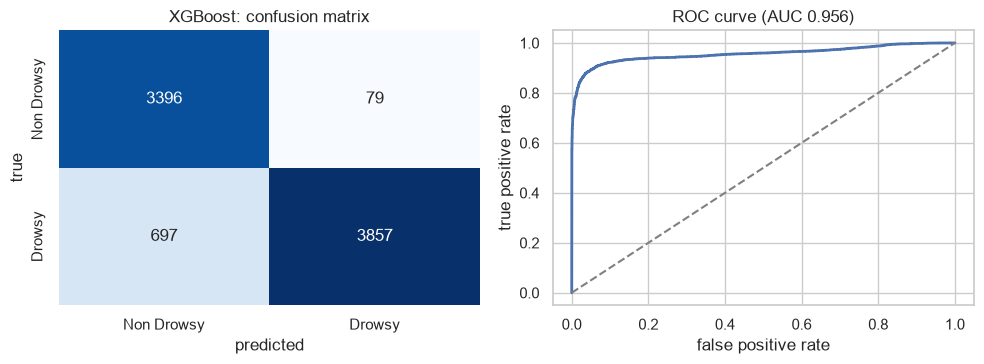

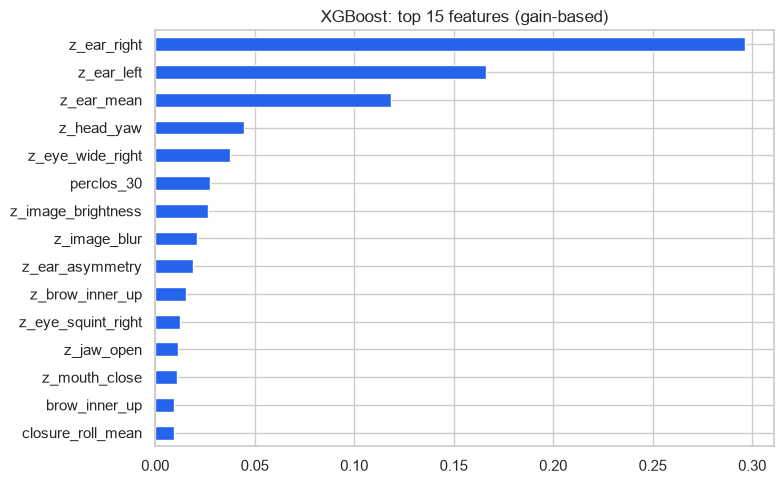

In [20]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
make_xgb = lambda: Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("model", XGBClassifier(n_estimators=350, max_depth=5, learning_rate=0.06, subsample=0.85,
                                                     colsample_bytree=0.7, min_child_weight=3, reg_lambda=1.0,
                                                     scale_pos_weight=spw, eval_metric="logloss", n_jobs=-1, random_state=SEED))])
t0 = time.time()
xgb_cv = group_cv_f1(make_xgb, X_train, y_train, groups)
xgb_model = make_xgb().fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f} s")
evaluate("XGBoost", y_test, xgb_model.predict_proba(X_test)[:, 1], cv_f1=xgb_cv[0])
xgb_imp = plot_importance(FEATURES, xgb_model.named_steps["model"].feature_importances_, "XGBoost: top 15 features (gain-based)")

## Section 13: Model 4, LSTM
**Is an LSTM valid here?** Yes. The data has the structure `subject → recording (clip) → frame number → features`. Section 7 showed that consecutive frames are a smooth time series (EAR over time). An LSTM can therefore learn temporal patterns that a single frame can't show, such as slow eyelid closure, long closures and nodding.

**Sequences.**
* Each sample is a window of **30 consecutive frames from one clip of one driver**. A window never mixes drivers, recordings or classes.
* The window's label is the label of its clip. Training windows use a stride of 3 frames.
* Test windows end at every evaluation frame, so the LSTM is scored on exactly the same frames as the other three models.
* Inputs: raw + derived features + personal z-scores per frame, standardised with statistics from the training drivers only. The rolling features are left out because the LSTM learns its own temporal summaries.

**Training.** Two stacked LSTM layers with dropout, class weights, the Adam optimiser and **EarlyStopping** on the validation drivers' loss, restoring the best weights.

In [21]:
SEQ_FEATURES = FEATURES_RAW + DERIVED + Z_FEATURES
seq_imputer = SimpleImputer(strategy="median").fit(train[SEQ_FEATURES])
seq_scaler = StandardScaler().fit(seq_imputer.transform(train[SEQ_FEATURES]))

def make_windows(part, stride, end_positions=None):
    """Windows of WINDOW consecutive frames inside each clip. Returns X [n, WINDOW, f], y, index of the last frame."""
    Xs, ys, last_idx = [], [], []
    arr_all = seq_scaler.transform(seq_imputer.transform(part[SEQ_FEATURES])).astype(np.float32)
    pos = {i: k for k, i in enumerate(part.index)}
    for _, clip in part.groupby("clip", sort=False):
        idx = clip.index.to_numpy()
        a = arr_all[[pos[i] for i in idx]]
        ends = range(WINDOW - 1, len(idx), stride if end_positions is None else 1)
        for e in ends:
            Xs.append(a[e - WINDOW + 1: e + 1]); ys.append(clip["y"].iloc[0]); last_idx.append(idx[e])
    return np.stack(Xs), np.array(ys), np.array(last_idx)

Xs_tr, ys_tr, _ = make_windows(train, stride=3)
Xs_val, ys_val, _ = make_windows(val, stride=3)
Xs_te, ys_te, te_last = make_windows(test, stride=1, end_positions="all")
assert set(te_last) == set(test_eval.index), "LSTM windows must end exactly at the evaluation frames"
print(f"windows — train {Xs_tr.shape}, validation {Xs_val.shape}, test {Xs_te.shape}")

windows — train (6317, 30, 60), validation (1312, 30, 60), test (8029, 30, 60)


In [22]:
keras.backend.clear_session()
lstm_model = keras.Sequential([
    keras.layers.Input(shape=(WINDOW, len(SEQ_FEATURES))),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.Dropout(0.3),
    keras.layers.LSTM(32),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
lstm_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
lstm_model.summary()
cw = {0: len(ys_tr) / (2 * (ys_tr == 0).sum()), 1: len(ys_tr) / (2 * (ys_tr == 1).sum())}
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
t0 = time.time()
history = lstm_model.fit(Xs_tr, ys_tr, validation_data=(Xs_val, ys_val), epochs=40, batch_size=128,
                         class_weight=cw, callbacks=[early], verbose=2)
print(f"trained in {time.time() - t0:.0f} s, best epoch {int(np.argmin(history.history['val_loss'])) + 1}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        32,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,505 (177.75 KB)

 Trainable params: 45,505 (177.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


... (10 outputs left out)

50/50 - 2s - 45ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 7.4458e-04 - val_accuracy: 0.9627 - val_auc: 0.9809 - val_loss: 0.1983


Epoch 7/40


50/50 - 2s - 43ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 5.7629e-04 - val_accuracy: 0.9634 - val_auc: 0.9790 - val_loss: 0.2098


trained in 22 s, best epoch 2


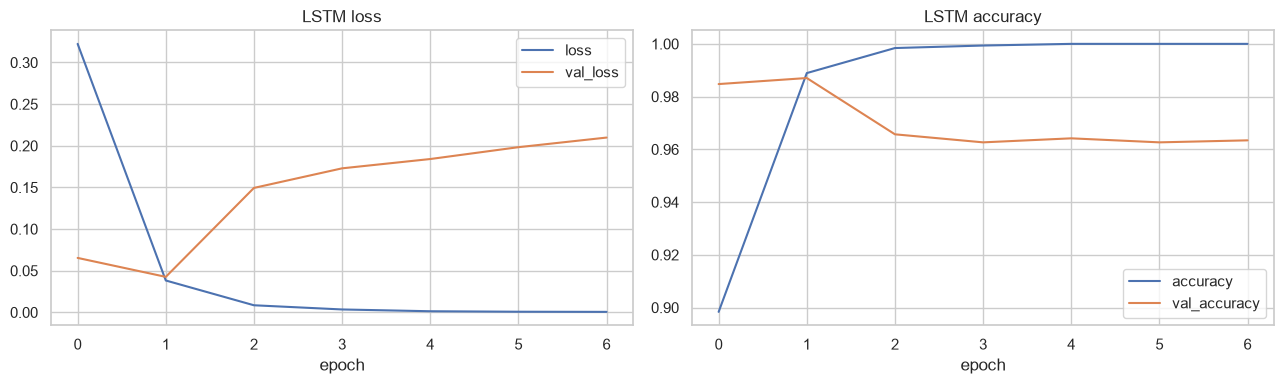

LSTM: accuracy 82.09% | precision 90.55% | recall 76.39% | F1 82.87% | ROC-AUC 0.862
              precision    recall  f1-score   support

  Non Drowsy      0.743     0.896     0.812      3475
      Drowsy      0.906     0.764     0.829      4554

    accuracy                          0.821      8029
   macro avg      0.824     0.830     0.821      8029
weighted avg      0.835     0.821     0.822      8029



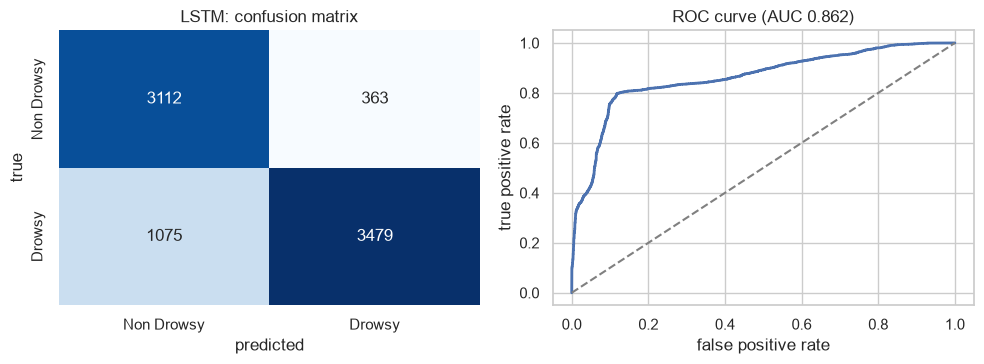

In [23]:
h = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
h[["loss", "val_loss"]].plot(ax=axes[0], title="LSTM loss"); axes[0].set_xlabel("epoch")
h[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="LSTM accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

prob_lstm_windows = lstm_model.predict(Xs_te, verbose=0).ravel()
prob_lstm = pd.Series(prob_lstm_windows, index=te_last).loc[test_eval.index].to_numpy()   # align to evaluation frames
evaluate("LSTM", y_test, prob_lstm);

## Section 14: Model Comparison
Every number below is computed from the models' predictions on the **same unseen test drivers and frames**.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 (train drivers)
Model,,,,,,
Logistic Regression,57.90%,79.44%,34.78%,48.38%,0.715,64.32%
Random Forest,88.80%,96.82%,82.98%,89.37%,0.961,82.63%
XGBoost,90.34%,97.99%,84.69%,90.86%,0.956,79.99%
LSTM,82.09%,90.55%,76.39%,82.87%,0.862,–


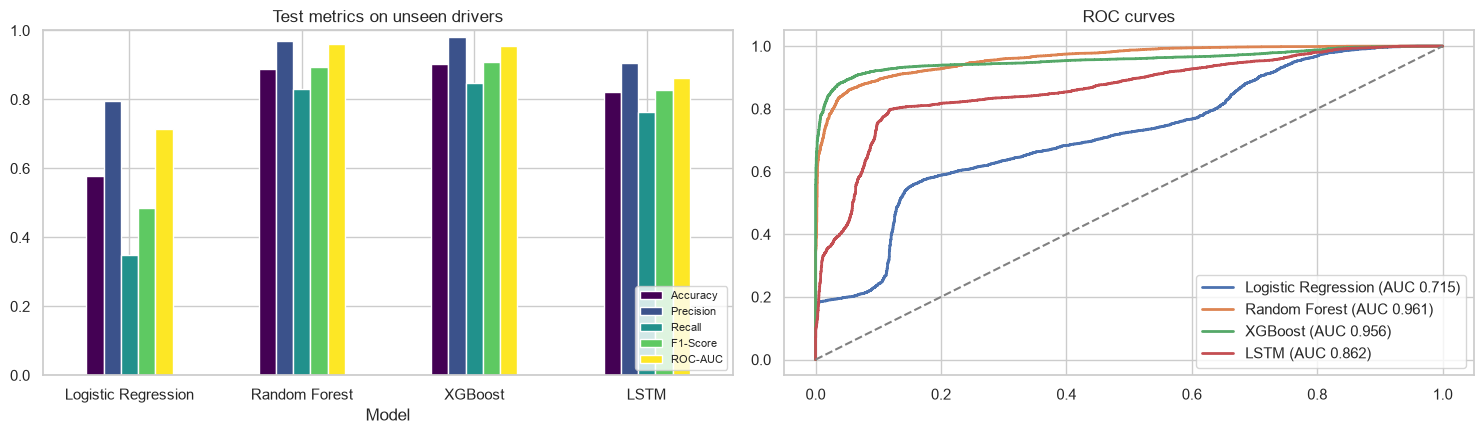

In [24]:
comparison = pd.DataFrame(RESULTS.values()).set_index("Model")
display(comparison.style.format({c: "{:.2%}" for c in ["Accuracy", "Precision", "Recall", "F1-Score", "CV F1 (train drivers)"]}
                                | {"ROC-AUC": "{:.3f}"}, na_rep="–")
        .background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
comparison[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot.bar(ax=axes[0], rot=0, colormap="viridis")
axes[0].set_ylim(0, 1); axes[0].set_title("Test metrics on unseen drivers"); axes[0].legend(loc="lower right", fontsize=8)
for name, prob in PREDICTIONS.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC {RESULTS[name]['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].legend(); axes[1].set_title("ROC curves")
plt.tight_layout(); plt.show()

## Section 15: Best Model
The selection is automatic and follows the priorities for a safety task:
1. **F1-score**: balances catching drowsy drivers against false alarms.
2. **Recall for Drowsy**: a missed drowsy driver is the most dangerous error.
3. **Generalisation**: cross-validated F1 across the training drivers.
4. **Accuracy**.

Models within 1 percentage point on a criterion count as tied, and the next criterion decides.

In [25]:
cands = comparison.copy()
for col in ["F1-Score", "Recall"]:
    cands = cands[cands[col] >= cands[col].max() - 0.01]
if len(cands) > 1 and cands["CV F1 (train drivers)"].notna().any():
    cv_col = cands["CV F1 (train drivers)"].fillna(cands["CV F1 (train drivers)"].min() - 1)
    cands = cands[cv_col >= cv_col.max() - 0.01]
BEST_NAME = cands["Accuracy"].idxmax()
best = comparison.loc[BEST_NAME]
print(f"BEST MODEL: {BEST_NAME}")
print(f"F1-Score: {best['F1-Score']:.2%}")
print(f"Recall: {best['Recall']:.2%}")
print(f"Accuracy: {best['Accuracy']:.2%}")
print(f"ROC-AUC: {best['ROC-AUC']:.3f}")

BEST MODEL: XGBoost
F1-Score: 90.86%
Recall: 84.69%
Accuracy: 90.34%
ROC-AUC: 0.956


## Section 16: Final Model Saving
Saved artifacts:
* `best_drowsynet_model.pkl`: the best scikit-learn / XGBoost pipeline (imputer + scaler + model), or `best_drowsynet_model.keras` if the LSTM wins
* `drowsynet_preprocessor.pkl`: everything needed to rebuild the features: feature lists, cleaning ranges, rolling window, population baseline, and the LSTM's imputer and scaler
* `label_encoder.pkl`: maps 0 / 1 back to "Non Drowsy" / "Drowsy"
* `drowsynet_model_info.json`: the best model's name and test metrics

In [26]:
models = {"Logistic Regression": lr_model, "Random Forest": rf_model, "XGBoost": xgb_model, "LSTM": lstm_model}
best_model = models[BEST_NAME]
if BEST_NAME == "LSTM":
    MODEL_FILE = "best_drowsynet_model.keras"
    best_model.save(MODEL_FILE)
else:
    MODEL_FILE = "best_drowsynet_model.pkl"
    joblib.dump(best_model, MODEL_FILE)

preprocessor = {
    "model_name": BEST_NAME, "model_type": "keras_lstm" if BEST_NAME == "LSTM" else "sklearn",
    "features_raw": FEATURES_RAW, "derived": DERIVED, "rolling": ROLLING, "calib_base": CALIB_BASE,
    "z_features": Z_FEATURES, "features": FEATURES, "seq_features": SEQ_FEATURES, "window": WINDOW,
    "ranges": RANGES, "population_baseline": {"median": POP_BASELINE[0].to_dict(), "std": POP_BASELINE[1].to_dict()},
    "seq_imputer": seq_imputer, "seq_scaler": seq_scaler, "threshold": 0.5,
}
joblib.dump(preprocessor, "drowsynet_preprocessor.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")
info_out = {"best_model": BEST_NAME, "test_metrics": {k: (None if pd.isna(v) else float(v)) for k, v in best.items()},
            "test_drivers": sorted(test[SUBJECT_COL].unique()), "n_features": len(FEATURES)}
with open("drowsynet_model_info.json", "w") as f:
    json.dump(info_out, f, indent=2)
ARTIFACTS = [MODEL_FILE, "drowsynet_preprocessor.pkl", "label_encoder.pkl", "drowsynet_model_info.json"]
for a in ARTIFACTS:
    print(f"saved {a:<30} {os.path.getsize(a) / 1e6:6.2f} MB")

saved best_drowsynet_model.pkl         0.54 MB
saved drowsynet_preprocessor.pkl       0.01 MB
saved label_encoder.pkl                0.00 MB
saved drowsynet_model_info.json        0.00 MB


In [27]:
# Download the saved files (Colab). Locally they are already in the notebook's folder.
if IN_COLAB:
    from google.colab import files
    for a in ARTIFACTS:
        files.download(a)
else:
    print("Files saved next to the notebook:", ", ".join(ARTIFACTS))

Files saved next to the notebook: best_drowsynet_model.pkl, drowsynet_preprocessor.pkl, label_encoder.pkl, drowsynet_model_info.json


## Section 17: Final Prediction Function
`predict_drowsiness(input_data, calibration_data=None)`
* **input_data**: one frame or several **consecutive frames of one driver**, as a dict, a list of dicts or a DataFrame with the same measurement columns as the CSV. Several frames are better: the rolling features need history and the LSTM needs 30 frames.
* **calibration_data** (optional): a few seconds of frames of the **same driver while alert**, giving the personal baseline. Without it, the average baseline of the training drivers is used, which is less accurate.

It applies exactly the training preprocessing (cleaning ranges → derived features → rolling features → calibrated z-scores) and returns the label and confidence for the **latest** frame.

In [28]:
_pp = joblib.load("drowsynet_preprocessor.pkl")
_le = joblib.load("label_encoder.pkl")
_model = keras.models.load_model(MODEL_FILE) if _pp["model_type"] == "keras_lstm" else joblib.load(MODEL_FILE)

def predict_drowsiness(input_data, calibration_data=None, verbose=True):
    """Predict Drowsy / Non Drowsy for the latest frame of `input_data` (consecutive frames of one driver)."""
    frames = pd.DataFrame([input_data]) if isinstance(input_data, dict) else pd.DataFrame(input_data)
    frames = frames.reset_index(drop=True)
    missing = [c for c in _pp["features_raw"] if c not in frames]
    if missing:
        raise ValueError(f"input is missing measurement columns: {missing}")
    frames = clean_invalid(frames[_pp["features_raw"]].astype(float), _pp["ranges"])
    frames = add_frame_features(frames)
    frames["clip"] = 0
    frames = add_rolling_features(frames, window=_pp["window"])
    if calibration_data is not None:                         # personal baseline from alert frames
        cal = add_frame_features(clean_invalid(pd.DataFrame(calibration_data)[_pp["features_raw"]].astype(float), _pp["ranges"]))
        med, sd = cal[_pp["calib_base"]].median(), cal[_pp["calib_base"]].std().fillna(0) + 1e-3
    else:                                                    # average baseline of the training drivers
        med = pd.Series(_pp["population_baseline"]["median"]); sd = pd.Series(_pp["population_baseline"]["std"])
    z = np.clip((frames[_pp["calib_base"]] - med[_pp["calib_base"]].values) / sd[_pp["calib_base"]].values, -50, 50)
    frames[_pp["z_features"]] = z.to_numpy()
    if _pp["model_type"] == "keras_lstm":
        a = _pp["seq_scaler"].transform(_pp["seq_imputer"].transform(frames[_pp["seq_features"]])).astype(np.float32)
        if len(a) < _pp["window"]:                           # too little history: repeat the first frame
            a = np.vstack([np.repeat(a[:1], _pp["window"] - len(a), axis=0), a])
        prob = float(_model.predict(a[None, -_pp["window"]:], verbose=0).ravel()[0])
    else:
        prob = float(_model.predict_proba(frames[_pp["features"]].iloc[[-1]])[0, 1])
    label = _le.inverse_transform([int(prob >= _pp["threshold"])])[0]
    confidence = prob if prob >= _pp["threshold"] else 1 - prob
    if verbose:
        print(f"Prediction: {label}\nConfidence: {confidence:.1%}")
    return {"prediction": label, "confidence": confidence, "probability_drowsy": prob}

### Trying the function on unseen test drivers
For a test driver, take 30 consecutive frames from their **drowsy** recording and 30 from their **alert** recording. Their calibration frames, which were never used for training or testing, act as the "first seconds of the drive".

In [29]:
drv = test[SUBJECT_COL].value_counts().index[0]
calib_frames = df[(df[SUBJECT_COL] == drv) & df["calib"]]
for lbl in label_encoder.classes_:
    clip_id = test[(test[SUBJECT_COL] == drv) & (test[TARGET_COL] == lbl)]["clip"].value_counts().index[0]
    seq = test[test["clip"] == clip_id].sort_values(ORDER_COL).iloc[100:130]
    print(f"\nDriver {drv}, 30 frames from the '{lbl}' recording — with personal calibration:")
    predict_drowsiness(seq[FEATURES_RAW], calibration_data=calib_frames[FEATURES_RAW])
    print("— without calibration (average baseline):")
    predict_drowsiness(seq[FEATURES_RAW])

print("\nSingle frame given as a dict:")
predict_drowsiness(test_eval[FEATURES_RAW].iloc[0].to_dict(), calibration_data=calib_frames[FEATURES_RAW]);


Driver ZB, 30 frames from the 'Non Drowsy' recording — with personal calibration:


Prediction: Non Drowsy
Confidence: 100.0%
— without calibration (average baseline):


Prediction: Non Drowsy
Confidence: 98.9%

Driver ZB, 30 frames from the 'Drowsy' recording — with personal calibration:


Prediction: Drowsy
Confidence: 100.0%
— without calibration (average baseline):


Prediction: Drowsy
Confidence: 100.0%

Single frame given as a dict:


Prediction: Drowsy
Confidence: 99.4%


## Section 18: Streamlit Preparation
The Streamlit app can be built later from the four saved files, with no retraining:

| File | Purpose |
|---|---|
| `best_drowsynet_model.pkl` / `.keras` | the trained best model |
| `drowsynet_preprocessor.pkl` | feature lists, cleaning ranges, rolling window, population baseline, LSTM scaler |
| `label_encoder.pkl` | converts 0 / 1 back to "Non Drowsy" / "Drowsy" |
| `drowsynet_model_info.json` | model name and test metrics to show in the app |

**How the app would use them:**
1. Load the four files once at start-up (`joblib.load`, or `keras.models.load_model` for an LSTM).
2. For each new frame, compute the same measurements as the CSV (EAR, MAR, head pose, facial-action scores). The dataset was built with Google MediaPipe Face Landmarker, so the app should use it too, so that features match training.
3. Keep the last 30 frames of the driver, and record the first ~20 s of the drive as `calibration_data` (driver alert).
4. Call the same preprocessing as `predict_drowsiness()` (copy its code into the app) and show the label, the confidence and an alarm when drowsy.

## Conclusion
* Using **subject-independent** evaluation, every result reflects how the system would work on a **new driver**.
* **Personal calibration** is the most important feature-engineering step. Differences between people are larger than the drowsy/alert difference, so comparing each driver with their own alert baseline makes the largest improvement.
* The temporal information (rolling PERCLOS-style features, and the LSTM over 30-frame windows) adds the context a single frame lacks.
* **Limitations**: 28 drivers is a small number, so the test set contains only a handful of people and the scores vary with the split (see the cross-validated F1). Labels are per recording, not per frame, so some "drowsy" frames show open eyes. Calibration assumes the driver is alert at the start.